In [1]:
import warnings
warnings.filterwarnings('ignore')

import os 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from enigmatoolbox.plotting import plot_cortical, plot_subcortical
from enigmatoolbox.utils.parcellation import parcel_to_surface
import nilearn.plotting

import sys
sys.path.append('..')

from helper.func import general_linear_model

In [ ]:
project_dir = os.path.abspath(os.path.join(os.getcwd(), '..'))
results_dir = os.path.join(project_dir, '...')

In [3]:
from matplotlib.colors import LinearSegmentedColormap
import matplotlib as mpl

my_rdbu = LinearSegmentedColormap.from_list(
    "my_rdbu", ["#174fa0", "#2f89c2", "#f7f7f7", "#df5948", "#ad0c28"], N=256)

try:
    mpl.colormaps.register(my_rdbu)
except ValueError:
    pass

## Left and right TLE

In [ ]:
demo = pd.read_csv(os.path.join(results_dir, '...', 'demo.csv'))
demo['Dx'] = pd.to_numeric(demo['Dx'], errors='coerce')

ctx_tle = pd.read_csv(os.path.join(results_dir, '...', 'ctx_tle.csv'), index_col=0)
sv_tle = pd.read_csv(os.path.join(results_dir, '...', 'sv_tle.csv'), index_col=0)

# Select the left and right TLE
idx_img = (ctx_tle.index.intersection(sv_tle.index))

# Left TLE (SDx = 0, 3, 5)
idx_left = demo.index[demo["SDx"].isin([0, 3, 5])]
idx_left = idx_img.intersection(idx_left)

demo_left = demo.loc[idx_left]
ctx_left  = ctx_tle.loc[idx_left]
sv_left   = sv_tle.loc[idx_left]

# Right TLE (SDx = 0, 4, 6)
idx_right = demo.index[demo["SDx"].isin([0, 4, 6])]
idx_right = idx_img.intersection(idx_right)

demo_right = demo.loc[idx_right]
ctx_right  = ctx_tle.loc[idx_right]
sv_right   = sv_tle.loc[idx_right]

### Effect of sex and diagnosis-sex interaction across cohorts

In [5]:
## glm comparison 
biomarker_datasets = {
    "tle_left":  {"demo": demo_left,  "ctx": ctx_left,  "sv": sv_left},
    "tle_right": {"demo": demo_right, "ctx": ctx_right, "sv": sv_right},
}

comparison_types = ["case_control", "sex_in_epi", "sex_in_hc", "sex_group_interaction"]

results = {epi: {b: {} for b in ["ctx", "sv"]} for epi in biomarker_datasets.keys()}

for epi, pack in biomarker_datasets.items():
    demo_sub = pack["demo"]

    for biomarker in ["ctx", "sv"]:
        biomarker_df = pack[biomarker]

        glm = general_linear_model(demo_sub, biomarker_df)
        df_name = f"{biomarker}_{epi}"

        for comparison_type in comparison_types:
            results[epi][biomarker][comparison_type] = glm.biomarker_comparison(
                df_name=df_name, comparison_type=comparison_type, age_col="Age",
                sex_col="Sex", icv_col="ICV", group_col="Dx")        

2026-05-28 10:39:57,951 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-05-28 10:39:57,957 - brainstat - WARNING - group has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-05-28 10:39:58,011 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-05-28 10:39:58,050 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variabl

In [6]:
# Reorganize results

metrics = ["t", "q", "cohen"]
epi_types = ["tle_left", "tle_right"]
biomarkers = ["ctx", "sv"]

comparison_types = [
    "case_control",
    "sex_in_epi",
    "sex_in_hc",
    "sex_group_interaction",
]

result_dicts = {}

for epi in epi_types:
    for biomarker in biomarkers:

        t_values = np.vstack([
            results[epi][biomarker][comp]["t_values"]
            for comp in comparison_types
        ])
        result_dicts[f"t_{epi}_{biomarker}"] = t_values

        q_values = np.vstack([
            results[epi][biomarker][comp]["q_values"]
            for comp in comparison_types
        ])
        result_dicts[f"q_{epi}_{biomarker}"] = q_values

        cohen_values = np.vstack([
            results[epi][biomarker][comp]["cohen_d"]
            for comp in comparison_types
        ])
        result_dicts[f"cohen_{epi}_{biomarker}"] = cohen_values


Sex-diagnosis interaction effects in cortical thickness

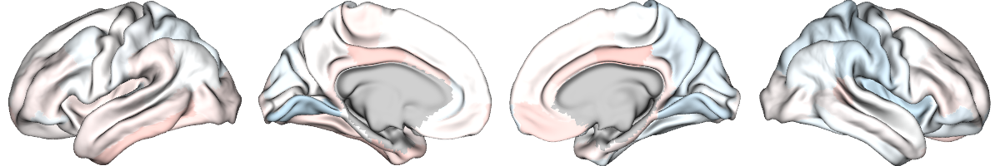

In [12]:
# plot cohen values in left TLE
# label_text = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

cohen_ctx_surf = parcel_to_surface(result_dicts['cohen_tle_left_ctx'][3], 'aparc_conte69')
cohen_ctx_surf[cohen_ctx_surf==0] = np.nan

plot_cortical(array_name=cohen_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

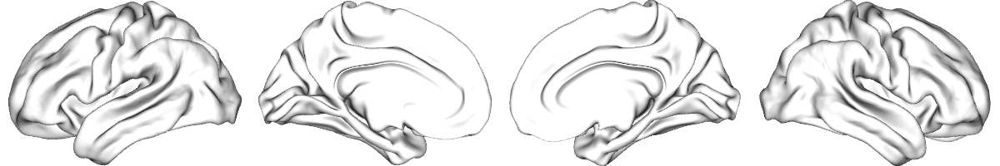

In [13]:
# plot p-sig areas

p_ctx_surf = parcel_to_surface(result_dicts['q_tle_left_ctx'][3], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

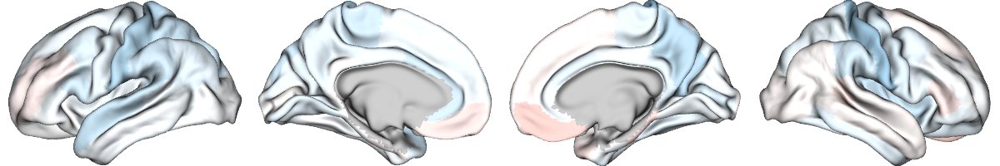

In [14]:
# plot cohen values in right TLE
# label_text = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

cohen_ctx_surf = parcel_to_surface(result_dicts['cohen_tle_right_ctx'][3], 'aparc_conte69')
cohen_ctx_surf[cohen_ctx_surf==0] = np.nan

plot_cortical(array_name=cohen_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

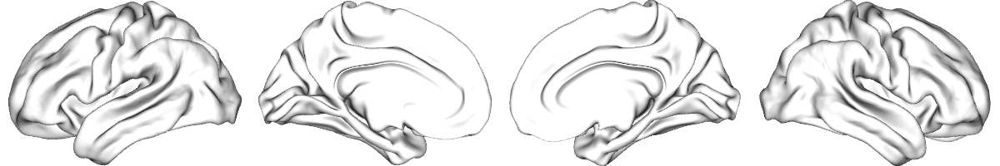

In [15]:
# plot p-sig areas

p_ctx_surf = parcel_to_surface(result_dicts['q_tle_right_ctx'][3], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

Sex effects in interaction: LTLE

In [16]:
# Check which cortical areas are significant — Left TLE (sex_group_interaction)
q_ctx_left = pd.Series(
    result_dicts["q_tle_left_ctx"][3],   
    index=ctx_tle.columns,
    name="qFDR"
)

sig_ctx_left = q_ctx_left[q_ctx_left < 0.05].index
sig_ctx_left

Index([], dtype='object')

In [17]:
# get the Cohen's d range — Left TLE (contrast index = 3)
result_dicts["cohen_tle_left_ctx"][3].min(), result_dicts["cohen_tle_left_ctx"][3].max()

(-0.04811349497799623, 0.05181175344531042)

Sex effects in interaction: right TLE

In [19]:
q_ctx_right = pd.Series(
    result_dicts["q_tle_right_ctx"][3],
    index=ctx_tle.columns,
    name="qFDR"
)

sig_ctx_right = q_ctx_right[q_ctx_right < 0.05].index
sig_ctx_right

Index([], dtype='object')

In [20]:
# Right TLE
result_dicts["cohen_tle_right_ctx"][3].min(), result_dicts["cohen_tle_right_ctx"][3].max()

(-0.07168602215636036, 0.048859982712945615)

Sex * disease duration interaction effects in subcortical volume

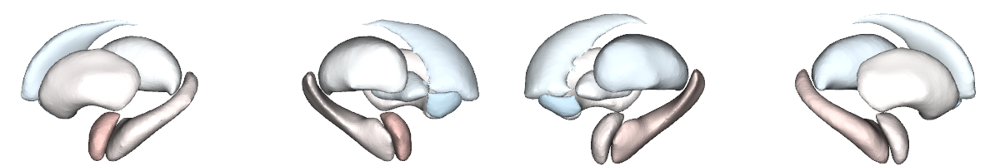

In [22]:
# plot cohen values in left TLE
# label_text = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

plot_subcortical(result_dicts['cohen_tle_left_sv'][3], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

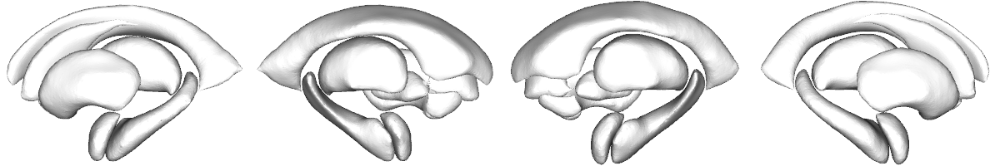

In [23]:
# plot p-sig areas

sig_mask = np.where(result_dicts['q_tle_left_sv'][3] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, nan_color=(1,1,1,1), interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

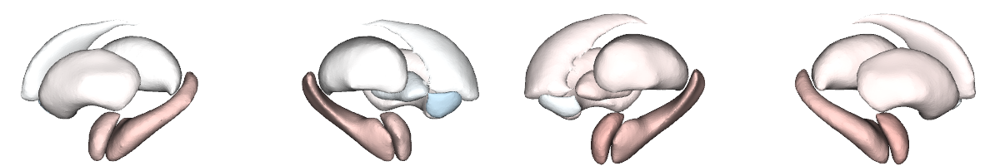

In [24]:
# plot cohen values in right TLE
# label_text = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

plot_subcortical(result_dicts['cohen_tle_right_sv'][3], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

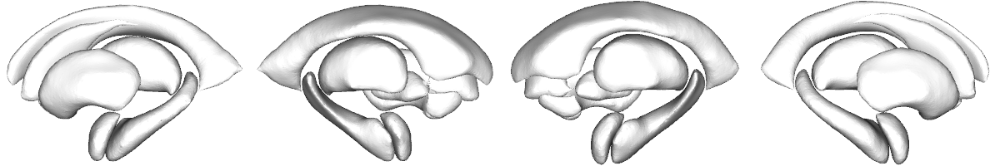

In [25]:
# plot p-sig areas

sig_mask = np.where(result_dicts['q_tle_left_sv'][3] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, nan_color=(1,1,1,1), interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [26]:
# Left TLE — sex * 'sex_group_interaction' (index = 3)

q_sv_left = pd.Series(
    result_dicts["q_tle_left_sv"][3],
    index=sv_tle.columns,
    name="pFDR"
)

q_sv_left[q_sv_left < 0.05].index

Index([], dtype='object')

In [27]:
# Right TLE 
q_sv_right = pd.Series(
    result_dicts["q_tle_right_sv"][3],
    index=sv_tle.columns,
    name="pFDR"
)

q_sv_right[q_sv_right < 0.05].index

Index([], dtype='object')

In [28]:
result_dicts["cohen_tle_left_sv"][3].min(), result_dicts["cohen_tle_left_sv"][3].max()

(-0.04498823374440035, 0.052038990758461134)

In [29]:
result_dicts["cohen_tle_right_sv"][3].min(), result_dicts["cohen_tle_right_sv"][3].max()

(-0.04884856640534435, 0.064355156862938)

### Correlation with clinical variables in left and right TLE

In [ ]:
demo = pd.read_csv(os.path.join(results_dir, '...', 'demo.csv'))
demo['Dx'] = pd.to_numeric(demo['Dx'], errors='coerce')

ctx_tle = pd.read_csv(os.path.join(results_dir, '...', 'ctx_tle_durill.csv'), index_col=0)
sv_tle = pd.read_csv(os.path.join(results_dir, '...', 'sv_tle_durill.csv'), index_col=0)

# select left and right TLE samples
idx_img = (ctx_tle.index.intersection(sv_tle.index))

# Left TLE (SDx = 3, 5)
idx_left = demo.index[demo["SDx"].isin([3, 5])]
idx_left = idx_img.intersection(idx_left)

demo_left = demo.loc[idx_left]
ctx_left  = ctx_tle.loc[idx_left]
sv_left   = sv_tle.loc[idx_left]

# Right TLE (SDx = 4, 6)
idx_right = demo.index[demo["SDx"].isin([4, 6])]
idx_right = idx_img.intersection(idx_right)

demo_right = demo.loc[idx_right]
ctx_right  = ctx_tle.loc[idx_right]
sv_right   = sv_tle.loc[idx_right]


### clinical correlate, and clinical variables-by sex interaction effects

In [9]:
# GLM comparison
biomarker_datasets = {
    "tle_left": {"demo": demo_left, "ctx": ctx_left, "sv": sv_left},
    "tle_right": {"demo": demo_right, "ctx": ctx_right, "sv": sv_right},
}

comparison_types = ["duration", "duration_sex_interaction", "ao", "ao_sex_interaction"]

results = {
    epi: {b: {} for b in ["ctx", "sv"]}
    for epi in biomarker_datasets.keys()
}

for epi, pack in biomarker_datasets.items():
    demo_sub = pack["demo"]

    for biomarker in ["ctx", "sv"]:
        biomarker_df = pack[biomarker]

        glm = general_linear_model(demo_sub, biomarker_df)
        df_name = f"{biomarker}_{epi}"

        for comparison_type in comparison_types:
            results[epi][biomarker][comparison_type] = glm.clinical_correlate(
                df_name=df_name, comparison_type=comparison_type, durill="durill",
                ao="ao", age="Age", sex="Sex", icv="ICV")

2026-05-28 10:49:17,572 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-05-28 10:49:17,604 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-05-28 10:49:17,638 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-05-28 10:49:17,663 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables

In [10]:
# Reorganize results 
metrics = ["t", "q", "cohen"]
epi_types = ["tle_left", "tle_right"]
biomarkers = ["ctx", "sv"]

comparison_types = ["duration", "duration_sex_interaction", "ao", "ao_sex_interaction"]

result_dicts = {}

for epi in epi_types:
    for biomarker in biomarkers:

        t_values = np.vstack([
            results[epi][biomarker][comp]["t_values"]
            for comp in comparison_types
        ])
        result_dicts[f"t_{epi}_{biomarker}"] = t_values

        q_values = np.vstack([
            results[epi][biomarker][comp]["q_values"]
            for comp in comparison_types
        ])
        result_dicts[f"q_{epi}_{biomarker}"] = q_values

        cohen_values = np.vstack([
            results[epi][biomarker][comp]["cohen_d"]
            for comp in comparison_types
        ])
        result_dicts[f"cohen_{epi}_{biomarker}"] = cohen_values

Sex * disease duration interaction effects in cortical thickness

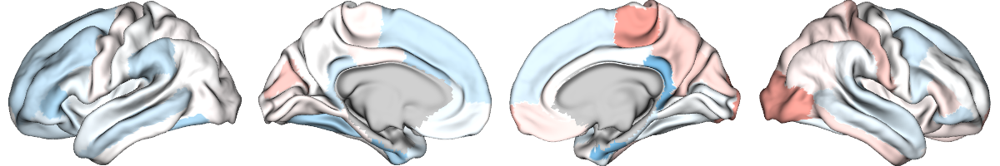

In [12]:
# plot cohen values in left TLE
# label_text = ['sex + durill', 'sex * durill', 'sex + ao', 'sex * ao']

cohen_ctx_surf = parcel_to_surface(result_dicts['cohen_tle_left_ctx'][1], 'aparc_conte69')
cohen_ctx_surf[cohen_ctx_surf==0] = np.nan

plot_cortical(array_name=cohen_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

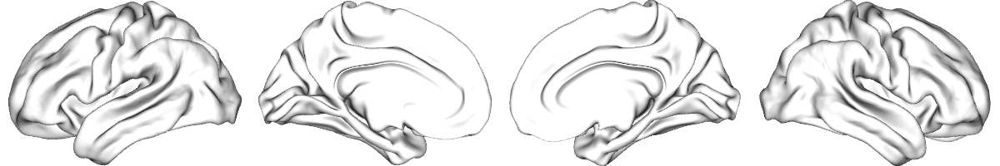

In [13]:
# plot p-sig areas

p_ctx_surf = parcel_to_surface(result_dicts['q_tle_left_ctx'][1], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

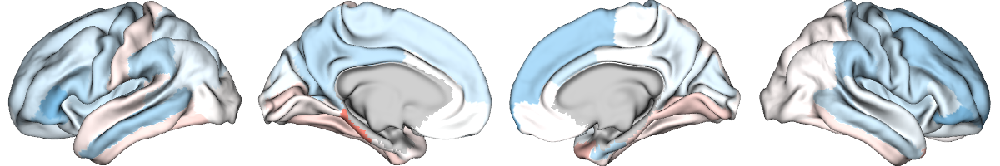

In [14]:
# plot cohen values in right TLE
# label_text = ['sex + durill', 'sex * durill', 'sex + ao', 'sex * ao']

cohen_ctx_surf = parcel_to_surface(result_dicts['cohen_tle_right_ctx'][1], 'aparc_conte69')
cohen_ctx_surf[cohen_ctx_surf==0] = np.nan

plot_cortical(array_name=cohen_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

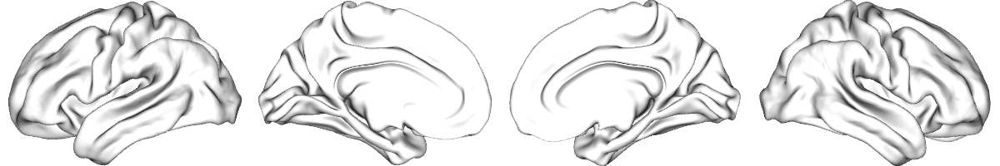

In [15]:
# plot p -sig areas

p_ctx_surf = parcel_to_surface(result_dicts['q_tle_right_ctx'][1], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [ ]:
# Left TLE
q_ctx_left = pd.Series(
    result_dicts["q_tle_left_ctx"][1],
    index=ctx_tle.columns,
    name="qFDR"
)

sig_ctx_left = q_ctx_left[q_ctx_left < 0.05].index
sig_ctx_left

Index([], dtype='object')

In [ ]:
# Right TLE
q_ctx_right = pd.Series(
    result_dicts["q_tle_right_ctx"][1],
    index=ctx_tle.columns,
    name="qFDR"
)

sig_ctx_right = q_ctx_right[q_ctx_right < 0.05].index
sig_ctx_right

Index([], dtype='object')

In [18]:
# LTLE
result_dicts["cohen_tle_left_ctx"][1].min(), result_dicts["cohen_tle_left_ctx"][1].max()

(-0.10728623050586343, 0.09674105726011961)

In [19]:
# RTLE
result_dicts["cohen_tle_right_ctx"][1].min(), result_dicts["cohen_tle_right_ctx"][1].max()

(-0.10402513674585705, 0.12480871667096269)

Sex * age of onset interaction effects cortical thickness

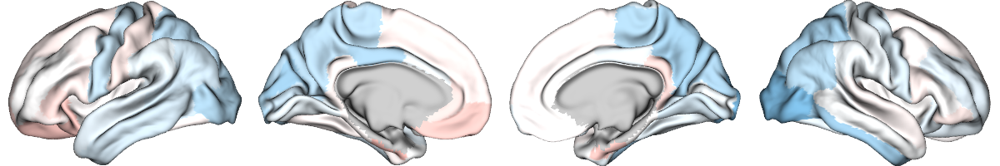

In [22]:
# plot cohen values in left TLE
# label_text = ['sex + durill', 'sex * durill', 'sex + ao', 'sex * ao']

cohen_ctx_surf = parcel_to_surface(result_dicts['cohen_tle_left_ctx'][3], 'aparc_conte69')
cohen_ctx_surf[cohen_ctx_surf==0] = np.nan

plot_cortical(array_name=cohen_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

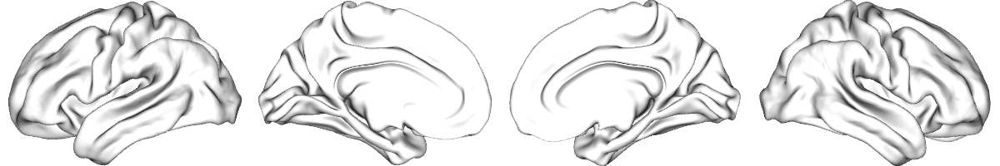

In [24]:
# plot p-sig areas

p_ctx_surf = parcel_to_surface(result_dicts['q_tle_left_ctx'][3], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

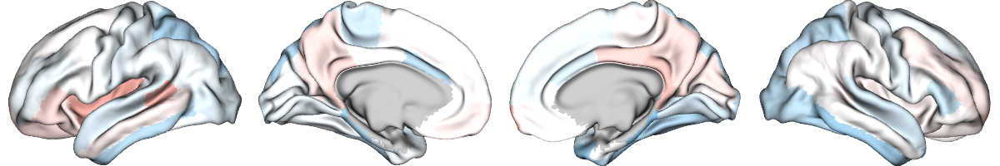

In [25]:
# plot cohen values in right TLE
# label_text = ['sex + durill', 'sex * durill', 'sex + ao', 'sex * ao']

cohen_ctx_surf = parcel_to_surface(result_dicts['cohen_tle_right_ctx'][3], 'aparc_conte69')
cohen_ctx_surf[cohen_ctx_surf==0] = np.nan

plot_cortical(array_name=cohen_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

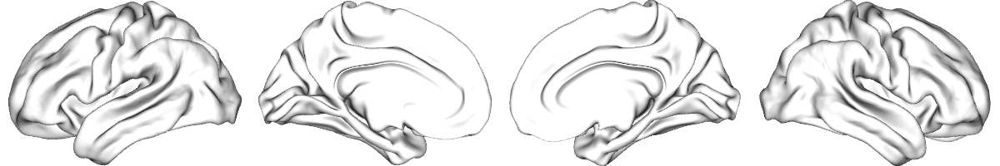

In [26]:
# plot p-sig areas

p_ctx_surf = parcel_to_surface(result_dicts['q_tle_right_ctx'][3], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [ ]:
# Left TLE 
q_ctx_left = pd.Series(
    result_dicts["q_tle_left_ctx"][3],
    index=ctx_tle.columns,
    name="qFDR"
)

sig_ctx_left = q_ctx_left[q_ctx_left < 0.05].index
sig_ctx_left

Index([], dtype='object')

In [ ]:
# Right TLE 
q_ctx_right = pd.Series(
    result_dicts["q_tle_right_ctx"][3],
    index=ctx_tle.columns,
    name="qFDR"
)

sig_ctx_right = q_ctx_right[q_ctx_right < 0.05].index
sig_ctx_right

Index([], dtype='object')

In [29]:
# LTLE
result_dicts["cohen_tle_left_ctx"][3].min(), result_dicts["cohen_tle_left_ctx"][3].max()

(-0.10427088294893368, 0.06760343972897746)

In [30]:
# RTLE
result_dicts["cohen_tle_right_ctx"][3].min(), result_dicts["cohen_tle_right_ctx"][3].max()

(-0.0943680483990947, 0.08505424712115135)

Sex * disease duration interaction effects in subcortical volume

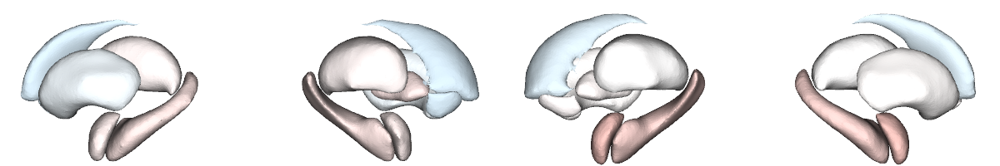

In [33]:
# plot cohen values in left TLE
# label_text = ['sex + durill', 'sex * durill', 'sex + ao', 'sex * ao']

plot_subcortical(result_dicts['cohen_tle_left_sv'][1], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

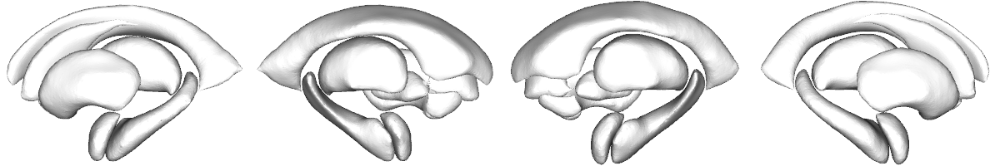

In [34]:
# plot p-sig areas

sig_mask = np.where(result_dicts['q_tle_left_sv'][1] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, nan_color=(1,1,1,1), interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

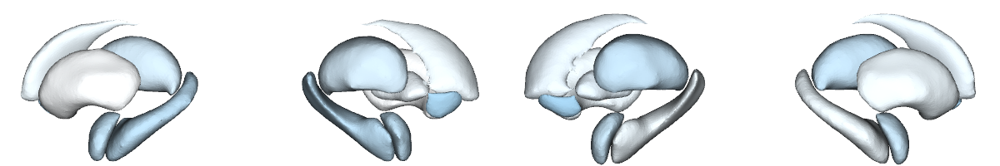

In [35]:
# plot cohen values in right TLE
# label_text = ['sex + durill', 'sex * durill', 'sex + ao', 'sex * ao']

plot_subcortical(result_dicts['cohen_tle_right_sv'][1], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

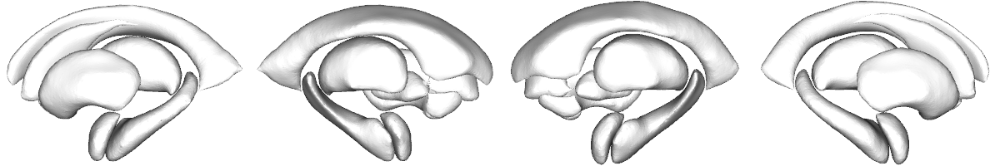

In [36]:
# plot p-sig areas

sig_mask = np.where(result_dicts['q_tle_right_sv'][1] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, nan_color=(1,1,1,1), interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [37]:
# Left TLE 

q_sv_left = pd.Series(
    result_dicts["q_tle_left_sv"][1],
    index=sv_tle.columns,
    name="pFDR"
)

q_sv_left[q_sv_left < 0.05].index

Index([], dtype='object')

In [38]:
# Right TLE 

q_sv_right = pd.Series(
    result_dicts["q_tle_right_sv"][1],
    index=sv_tle.columns,
    name="pFDR"
)

q_sv_right[q_sv_right < 0.05].index

Index([], dtype='object')

In [39]:
result_dicts["cohen_tle_left_sv"][1].min(), result_dicts["cohen_tle_left_sv"][1].max()

(-0.03437295050798168, 0.05719945665807051)

In [40]:
result_dicts["cohen_tle_right_sv"][1].min(), result_dicts["cohen_tle_right_sv"][1].max()

(-0.07606487088144452, -0.005255742755596826)

Sex* age of onset interaction effects in subcortical volume

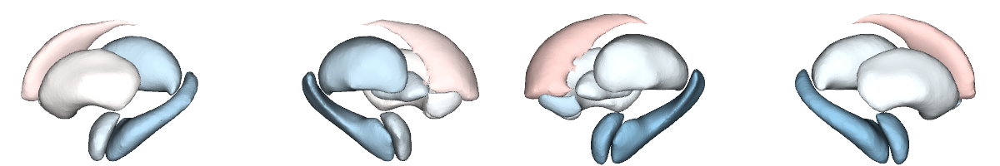

In [43]:
# plot cohen values in left TLE
# label_text = ['sex + durill', 'sex * durill', 'sex + ao', 'sex * ao']

plot_subcortical(result_dicts['cohen_tle_left_sv'][3], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

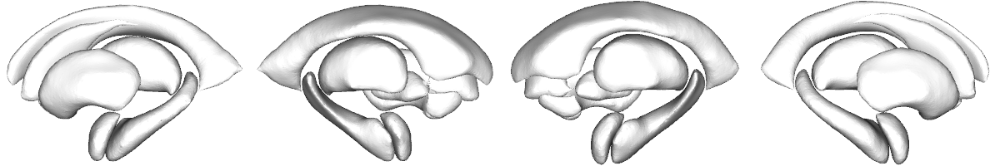

In [44]:
# plot p-sig areas

sig_mask = np.where(result_dicts['q_tle_left_sv'][3] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, nan_color=(1,1,1,1), interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

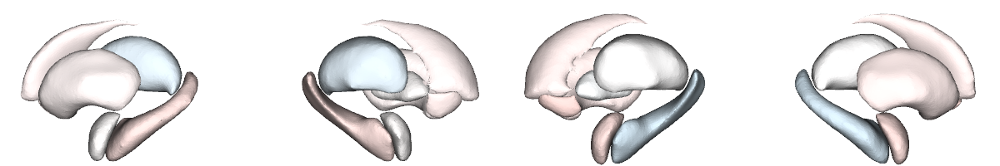

In [45]:
# plot cohen values in right TLE
# label_text = ['sex + durill', 'sex * durill', 'sex + ao', 'sex * ao']

plot_subcortical(result_dicts['cohen_tle_right_sv'][3], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

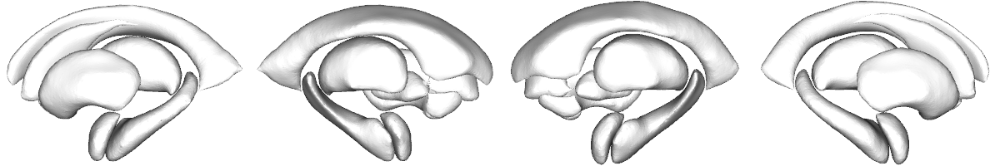

In [ ]:
# plot p-sig areas
sig_mask = np.where(result_dicts['q_tle_right_sv'][1] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, nan_color=(1,1,1,1), interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [47]:
# Left TLE

q_sv_left = pd.Series(
    result_dicts["q_tle_left_sv"][3],
    index=sv_tle.columns,
    name="pFDR"
)

q_sv_left[q_sv_left < 0.05].index

Index([], dtype='object')

In [48]:
# Right TLE 

q_sv_right = pd.Series(
    result_dicts["q_tle_right_sv"][3],
    index=sv_tle.columns,
    name="pFDR"
)

q_sv_right[q_sv_right < 0.05].index

Index([], dtype='object')

In [49]:
result_dicts["cohen_tle_left_sv"][3].min(), result_dicts["cohen_tle_left_sv"][3].max()

(-0.08816899330547663, 0.04640182365570835)

In [50]:
result_dicts["cohen_tle_right_sv"][3].min(), result_dicts["cohen_tle_right_sv"][3].max()

(-0.03396029920069997, 0.03889271492598838)

## MTS and Non-lesional TLE

In [ ]:
demo = pd.read_csv(os.path.join(results_dir, '...', 'demo.csv'))
demo['Dx'] = pd.to_numeric(demo['Dx'], errors='coerce')

ctx_tle = pd.read_csv(os.path.join(results_dir, '...', 'ctx_tle.csv'), index_col=0)
sv_tle = pd.read_csv(os.path.join(results_dir, '...', 'sv_tle.csv'), index_col=0)

# Sort out the MTS and Non-lesional samples
idx_img = (ctx_tle.index.intersection(sv_tle.index))

# MTS TLE (SDx = 3, 4)
idx_mts = demo.index[demo["SDx"].isin([0, 3, 4])]
idx_mts = idx_img.intersection(idx_mts)

demo_mts = demo.loc[idx_mts]
ctx_mts  = ctx_tle.loc[idx_mts]
sv_mts   = sv_tle.loc[idx_mts]

# Non-lesional TLE (SDx = 5, 6)
idx_nonlesional = demo.index[demo["SDx"].isin([0, 5, 6])]
idx_nonlesional = idx_img.intersection(idx_nonlesional)

demo_nonlesional = demo.loc[idx_nonlesional]
ctx_nonlesional  = ctx_tle.loc[idx_nonlesional]
sv_nonlesional   = sv_tle.loc[idx_nonlesional]

### Effect of sex and diagnosis-sex interaction across cohorts

In [33]:
## glm comparison 
biomarker_datasets = {
    "tle_mts": {"demo": demo_mts, "ctx": ctx_mts, "sv": sv_mts},
    "tle_nonlesional": {"demo": demo_nonlesional, "ctx": ctx_nonlesional, "sv": sv_nonlesional},
}

comparison_types = ["case_control", "sex_in_epi", "sex_in_hc", "sex_group_interaction"]

results = {
    epi: {b: {} for b in ["ctx", "sv"]}
    for epi in biomarker_datasets.keys()
}

for epi, pack in biomarker_datasets.items():
    demo_sub = pack["demo"]

    for biomarker in ["ctx", "sv"]:
        biomarker_df = pack[biomarker]

        glm = general_linear_model(demo_sub, biomarker_df)
        df_name = f"{biomarker}_{epi}"

        for comparison_type in comparison_types:
            results[epi][biomarker][comparison_type] = glm.biomarker_comparison(
                df_name=df_name, comparison_type=comparison_type, age_col="Age",
                sex_col="Sex", icv_col="ICV", group_col="Dx")

2026-05-28 10:19:28,179 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-05-28 10:19:28,186 - brainstat - WARNING - group has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.


2026-05-28 10:19:28,248 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-05-28 10:19:28,273 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-05-28 10:19:28,302 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-05-28 10:19:28,309 - brainstat - WARNING - group has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variabl

In [ ]:
# Reorganize results 
metrics = ["t", "q", "cohen"]
epi_types = ["tle_mts", "tle_nonlesional"]
biomarkers = ["ctx", "sv"]

comparison_types = ["case_control", "sex_in_epi", "sex_in_hc", "sex_group_interaction"]

result_dicts = {}

for epi in epi_types:
    for biomarker in biomarkers:

        t_values = np.vstack([
            results[epi][biomarker][comp]["t_values"]
            for comp in comparison_types
        ])
        result_dicts[f"t_{epi}_{biomarker}"] = t_values

        q_values = np.vstack([
            results[epi][biomarker][comp]["q_values"]
            for comp in comparison_types
        ])
        result_dicts[f"q_{epi}_{biomarker}"] = q_values

        cohen_values = np.vstack([
            results[epi][biomarker][comp]["cohen_d"]
            for comp in comparison_types
        ])
        result_dicts[f"cohen_{epi}_{biomarker}"] = cohen_values


Sex diagnosis interaction effects in cortical thickness

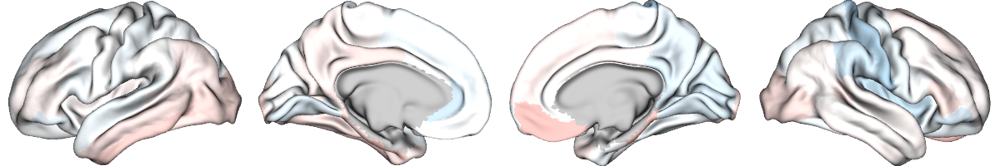

In [39]:
# plot cohen values in MTS TLE
# label_text = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

cohen_ctx_surf = parcel_to_surface(result_dicts['cohen_tle_mts_ctx'][3], 'aparc_conte69')
cohen_ctx_surf[cohen_ctx_surf==0] = np.nan

plot_cortical(array_name=cohen_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

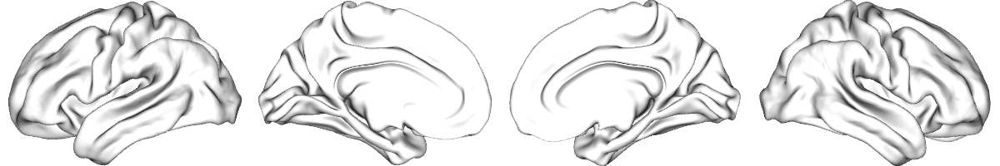

In [40]:
# plot p-sig areas

p_ctx_surf = parcel_to_surface(result_dicts['q_tle_mts_ctx'][3], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

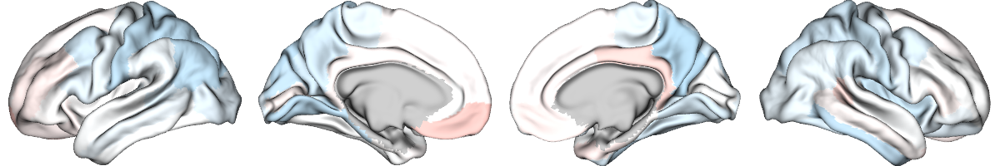

In [41]:
# plot cohen values in nonlesional TLE
# label_text = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

cohen_ctx_surf = parcel_to_surface(result_dicts['cohen_tle_nonlesional_ctx'][3], 'aparc_conte69')
cohen_ctx_surf[cohen_ctx_surf==0] = np.nan

plot_cortical(array_name=cohen_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

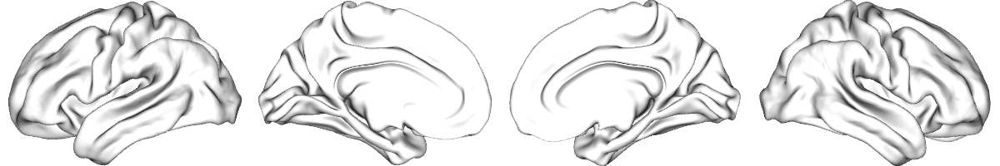

In [42]:
# plot p-sig areas
p_ctx_surf = parcel_to_surface(result_dicts['q_tle_nonlesional_ctx'][3], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [43]:
# Check which cortical areas are significant — MTS TLE (sex_group_interaction)
q_ctx_mts = pd.Series(
    result_dicts["q_tle_mts_ctx"][3],   # sex_group_interaction
    index=ctx_tle.columns,
    name="qFDR"
)

sig_ctx_mts = q_ctx_mts[q_ctx_mts < 0.05].index
sig_ctx_mts

Index([], dtype='object')

In [44]:
# get the Cohen's d range — MTS TLE (contrast index = 3)
result_dicts["cohen_tle_mts_ctx"][3].min(), result_dicts["cohen_tle_mts_ctx"][3].max()

(-0.05749860923438827, 0.06045701568811297)

Sex effects in interaction: TLE-nonlesional

In [46]:
q_ctx_nonlesional = pd.Series(
    result_dicts["q_tle_nonlesional_ctx"][3],
    index=ctx_tle.columns,
    name="qFDR"
)

sig_ctx_nonlesional = q_ctx_nonlesional[q_ctx_nonlesional < 0.05].index
sig_ctx_nonlesional

Index([], dtype='object')

In [47]:
# Non-lesional TLE
result_dicts["cohen_tle_nonlesional_ctx"][3].min(), result_dicts["cohen_tle_nonlesional_ctx"][3].max()

(-0.0599464386477607, 0.059946737242048846)

Sex diagnosis interaction effects in subcortical volume

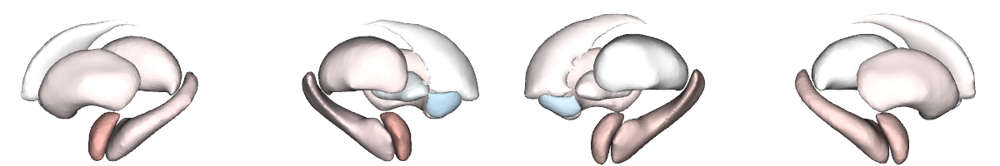

In [49]:
# plot cohen values in mts TLE
# label_text = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

plot_subcortical(result_dicts['cohen_tle_mts_sv'][3], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

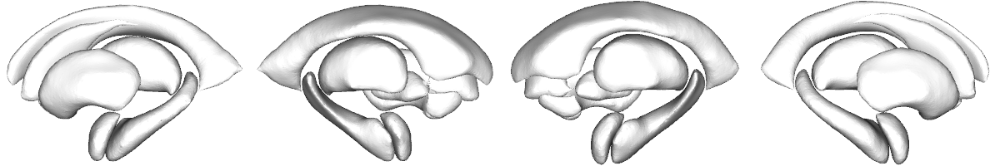

In [50]:
# plot p-sig areas
sig_mask = np.where(result_dicts['q_tle_mts_sv'][3] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, nan_color=(1,1,1,1), interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

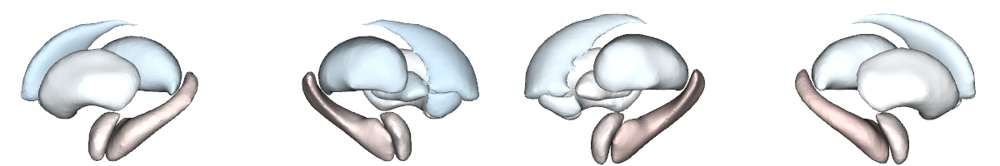

In [51]:
# plot cohen values in nonlesional TLE
# label_text = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

plot_subcortical(result_dicts['cohen_tle_nonlesional_sv'][3], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

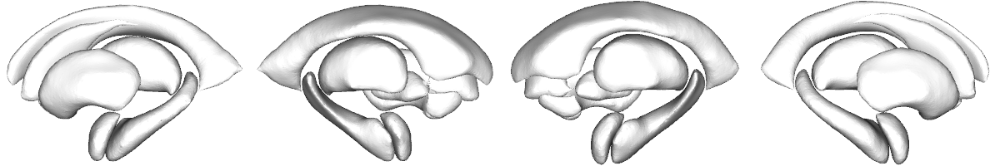

In [52]:
# plot p-sig areas
sig_mask = np.where(result_dicts['q_tle_nonlesional_sv'][3] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, nan_color=(1,1,1,1), interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [53]:
# MTS TLE
q_sv_left = pd.Series(
    result_dicts["q_tle_mts_sv"][3],
    index=sv_tle.columns,
    name="pFDR"
)

q_sv_left[q_sv_left < 0.05].index

Index([], dtype='object')

In [54]:
# nonlesional TLE 
q_sv_right = pd.Series(
    result_dicts["q_tle_nonlesional_sv"][3],
    index=sv_tle.columns,
    name="pFDR"
)

q_sv_right[q_sv_right < 0.05].index

Index([], dtype='object')

In [55]:
result_dicts["cohen_tle_mts_sv"][3].min(), result_dicts["cohen_tle_mts_sv"][3].max()

(-0.050170097238157754, 0.07321761184116544)

In [56]:
result_dicts["cohen_tle_nonlesional_sv"][3].min(), result_dicts["cohen_tle_nonlesional_sv"][3].max()

(-0.04167725335395219, 0.03352503854020943)

### Correlation with clinical variables in MTS and Non-lesional TLE

In [ ]:
demo = pd.read_csv(os.path.join(results_dir, '...', 'demo.csv'))
demo['Dx'] = pd.to_numeric(demo['Dx'], errors='coerce')

ctx_tle = pd.read_csv(os.path.join(results_dir, '...', 'ctx_tle_durill.csv'), index_col=0)
sv_tle = pd.read_csv(os.path.join(results_dir, '...', 'sv_tle_durill.csv'), index_col=0)

# Select the mts and non-lesional TLE participants
idx_img = (ctx_tle.index.intersection(sv_tle.index))

# MTS TLE
idx_mts = demo.index[demo["SDx"].isin([3, 4])]
idx_mts = idx_img.intersection(idx_mts)

demo_mts = demo.loc[idx_mts]
ctx_mts  = ctx_tle.loc[idx_mts]
sv_mts   = sv_tle.loc[idx_mts]

# Non-lesional TLE
idx_nonlesional = demo.index[demo["SDx"].isin([5, 6])]
idx_nonlesional = idx_img.intersection(idx_nonlesional)

demo_nonlesional = demo.loc[idx_nonlesional]
ctx_nonlesional  = ctx_tle.loc[idx_nonlesional]
sv_nonlesional   = sv_tle.loc[idx_nonlesional]

In [61]:
# glm comparison
biomarker_datasets = {
    "tle_mts": {"demo": demo_mts, "ctx": ctx_mts, "sv": sv_mts},
    "tle_nonlesional": {"demo": demo_nonlesional, "ctx": ctx_nonlesional, "sv": sv_nonlesional},
}

comparison_types = ["duration", "duration_sex_interaction", "ao", "ao_sex_interaction"]

results = {
    epi: {b: {} for b in ["ctx", "sv"]}
    for epi in biomarker_datasets.keys()
}

for epi, pack in biomarker_datasets.items():
    demo_sub = pack["demo"]

    for biomarker in ["ctx", "sv"]:
        biomarker_df = pack[biomarker]

        glm = general_linear_model(demo_sub, biomarker_df)
        df_name = f"{biomarker}_{epi}"

        for comparison_type in comparison_types:
            results[epi][biomarker][comparison_type] = glm.clinical_correlate(
                df_name=df_name, comparison_type=comparison_type, durill="durill",
                ao="ao", age="Age", sex="Sex", icv="ICV")

2026-05-28 10:31:11,037 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-05-28 10:31:11,072 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.


2026-05-28 10:31:11,107 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-05-28 10:31:11,133 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-05-28 10:31:11,167 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-05-28 10:31:11,200 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables

In [62]:
# Reorganize results 
metrics = ["t", "q", "cohen"]
epi_types = ["tle_mts", "tle_nonlesional"]
biomarkers = ["ctx", "sv"]

comparison_types = ["duration", "duration_sex_interaction", "ao", "ao_sex_interaction"]

result_dicts = {}

for epi in epi_types:
    for biomarker in biomarkers:

        t_values = np.vstack([
            results[epi][biomarker][comp]["t_values"]
            for comp in comparison_types
        ])
        result_dicts[f"t_{epi}_{biomarker}"] = t_values

        q_values = np.vstack([
            results[epi][biomarker][comp]["q_values"]
            for comp in comparison_types
        ])
        result_dicts[f"q_{epi}_{biomarker}"] = q_values

        cohen_values = np.vstack([
            results[epi][biomarker][comp]["cohen_d"]
            for comp in comparison_types
        ])
        result_dicts[f"cohen_{epi}_{biomarker}"] = cohen_values


Sex * disease duration interaction effects in cortical thickness

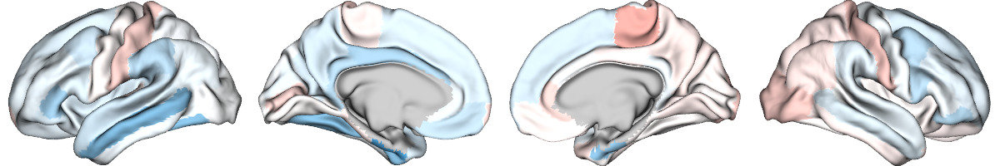

In [64]:
# plot cohen values in MTS TLE
# label_text = ['sex + durill', 'sex * durill', 'sex + ao', 'sex * ao']

cohen_ctx_surf = parcel_to_surface(result_dicts['cohen_tle_mts_ctx'][1], 'aparc_conte69')
cohen_ctx_surf[cohen_ctx_surf==0] = np.nan

plot_cortical(array_name=cohen_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

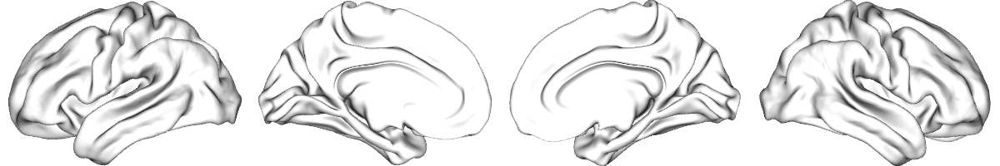

In [65]:
# plot p-sig areas

p_ctx_surf = parcel_to_surface(result_dicts['q_tle_mts_ctx'][1], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

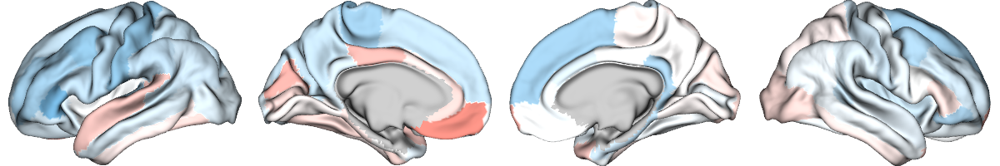

In [66]:
# plot cohen values in nonlesional TLE
# label_text = ['sex + durill', 'sex * durill', 'sex + ao', 'sex * ao']

cohen_ctx_surf = parcel_to_surface(result_dicts['cohen_tle_nonlesional_ctx'][1], 'aparc_conte69')
cohen_ctx_surf[cohen_ctx_surf==0] = np.nan

plot_cortical(array_name=cohen_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

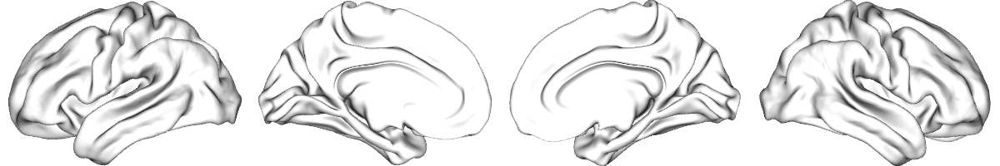

In [67]:
# plot p-sig areas

p_ctx_surf = parcel_to_surface(result_dicts['q_tle_nonlesional_ctx'][1], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [ ]:
# MTS — sex * durill (index = 1)
q_ctx_mts = pd.Series(
    result_dicts["q_tle_mts_ctx"][1],
    index=ctx_tle.columns,
    name="qFDR"
)

sig_ctx_mts = q_ctx_mts[q_ctx_mts < 0.05].index
sig_ctx_mts

Index([], dtype='object')

In [70]:
# Non-lesional — sex * durill (index = 1)

q_ctx_nonlesional = pd.Series(
    result_dicts["q_tle_nonlesional_ctx"][1],
    index=ctx_tle.columns,
    name="qFDR"
)

sig_ctx_nonlesional = q_ctx_nonlesional[q_ctx_nonlesional < 0.05].index
sig_ctx_nonlesional

Index([], dtype='object')

In [71]:
# MTS
result_dicts["cohen_tle_mts_ctx"][1].min(), result_dicts["cohen_tle_mts_ctx"][1].max()

(-0.13949163403802864, 0.08155636239788237)

In [72]:
# Non-lesional
result_dicts["cohen_tle_nonlesional_ctx"][1].min(), result_dicts["cohen_tle_nonlesional_ctx"][1].max()

(-0.10893895941388215, 0.11362805795065584)

Sex * age of onset interaction effects in cortical thickness

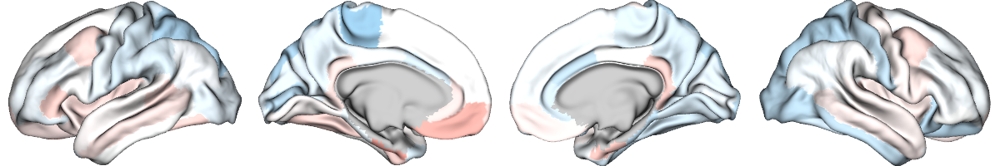

In [75]:
# plot cohen values in MTS TLE
# label_text = ['sex + durill', 'sex * durill', 'sex + ao', 'sex * ao']

cohen_ctx_surf = parcel_to_surface(result_dicts['cohen_tle_mts_ctx'][3], 'aparc_conte69')
cohen_ctx_surf[cohen_ctx_surf==0] = np.nan

plot_cortical(array_name=cohen_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

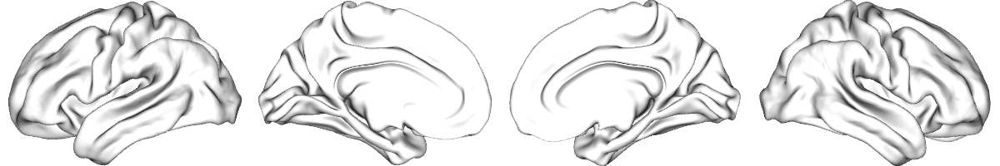

In [76]:
# plot p-sig areas

p_ctx_surf = parcel_to_surface(result_dicts['q_tle_mts_ctx'][3], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

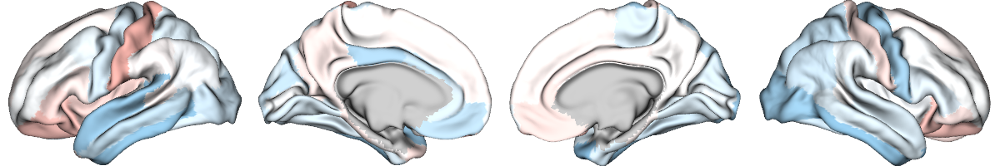

In [77]:
# plot cohen values in nonlesional TLE
# label_text = ['sex + durill', 'sex * durill', 'sex + ao', 'sex * ao']

cohen_ctx_surf = parcel_to_surface(result_dicts['cohen_tle_nonlesional_ctx'][3], 'aparc_conte69')
cohen_ctx_surf[cohen_ctx_surf==0] = np.nan

plot_cortical(array_name=cohen_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

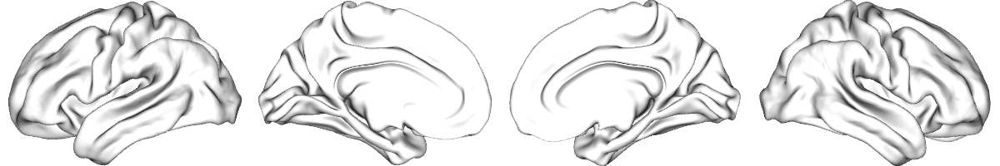

In [78]:
# plot p-sig areas

p_ctx_surf = parcel_to_surface(result_dicts['q_tle_nonlesional_ctx'][1], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [79]:
# MTS 
q_ctx_mts = pd.Series(
    result_dicts["q_tle_mts_ctx"][3],
    index=ctx_tle.columns,
    name="pFDR"
)

q_ctx_mts[q_ctx_mts < 0.05].index

Index([], dtype='object')

In [ ]:
# Non-lesional
q_ctx_nonlesional = pd.Series(
    result_dicts["q_tle_nonlesional_ctx"][3],
    index=ctx_tle.columns,
    name="pFDR"
)

q_ctx_nonlesional[q_ctx_nonlesional < 0.05].index

Index([], dtype='object')

In [81]:
result_dicts["cohen_tle_mts_ctx"][3].min(), result_dicts["cohen_tle_mts_ctx"][3].max()

(-0.0782620678483832, 0.08952092915158662)

In [82]:
result_dicts["cohen_tle_nonlesional_ctx"][3].min(), result_dicts["cohen_tle_nonlesional_ctx"][3].max()

(-0.09168696630874755, 0.07504361173938548)

Sex * disease duration interaction effects in subcortical volume

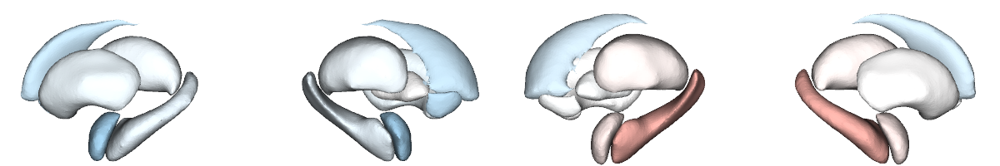

In [85]:
# plot cohen values in mts TLE
# label_text = ['sex + durill', 'sex * durill', 'sex + ao', 'sex * ao']

plot_subcortical(result_dicts['cohen_tle_mts_sv'][1], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

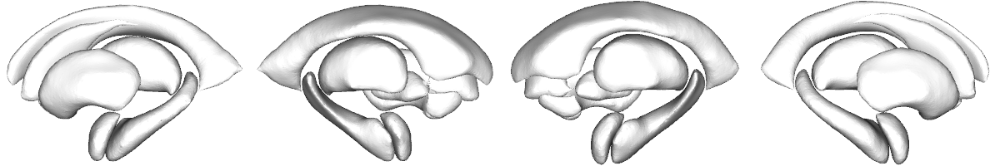

In [ ]:
# plot p-sig areas
sig_mask = np.where(result_dicts['q_tle_mts_sv'][1] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, nan_color=(1,1,1,1), interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

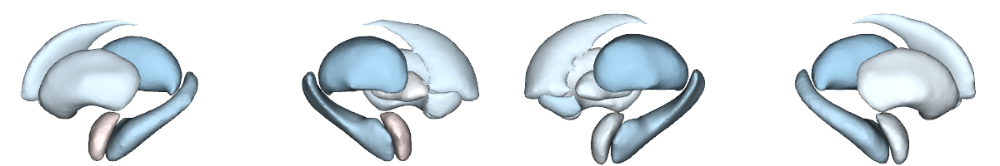

In [87]:
# plot cohen values in nonlesional TLE
# label_text = ['sex + durill', 'sex * durill', 'sex + ao', 'sex * ao']

plot_subcortical(result_dicts['cohen_tle_nonlesional_sv'][1], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

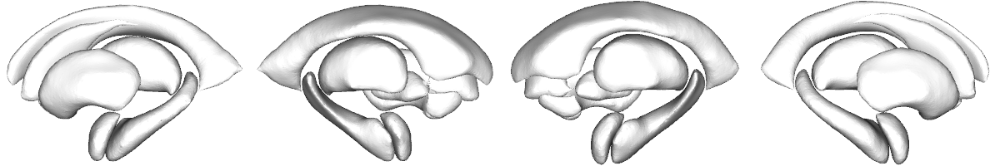

In [88]:
# plot p-sig areas
sig_mask = np.where(result_dicts['q_tle_nonlesional_sv'][1] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, nan_color=(1,1,1,1), interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [ ]:
# mts TLE — sex * disease duration 

q_sv_left = pd.Series(
    result_dicts["q_tle_mts_sv"][1],
    index=sv_tle.columns,
    name="pFDR"
)

q_sv_left[q_sv_left < 0.05].index

Index([], dtype='object')

In [90]:
# nonlesional TLE 

q_sv_right = pd.Series(
    result_dicts["q_tle_nonlesional_sv"][1],
    index=sv_tle.columns,
    name="pFDR"
)

q_sv_right[q_sv_right < 0.05].index

Index([], dtype='object')

In [91]:
result_dicts["cohen_tle_mts_sv"][1].min(), result_dicts["cohen_tle_mts_sv"][1].max()

(-0.07729094292267823, 0.08193660052468489)

In [92]:
result_dicts["cohen_tle_nonlesional_sv"][1].min(), result_dicts["cohen_tle_nonlesional_sv"][1].max()

(-0.07616739303991402, 0.020892028416472076)

Sex* age of onset interaction effects in subcortical volume

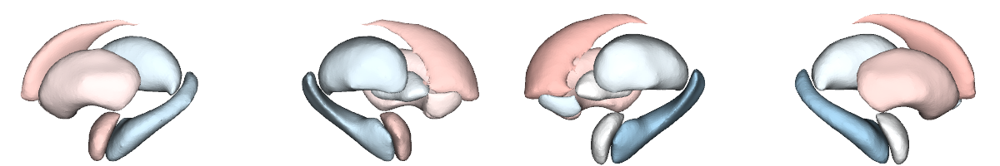

In [95]:
# plot cohen values in mts TLE
# label_text = ['sex + durill', 'sex * durill', 'sex + ao', 'sex * ao']

plot_subcortical(result_dicts['cohen_tle_mts_sv'][3], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

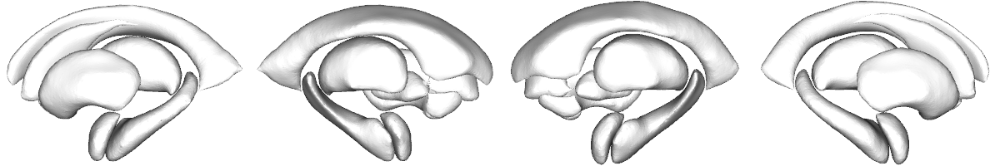

In [ ]:
# plot p-sig areas
sig_mask = np.where(result_dicts['q_tle_mts_sv'][3] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, nan_color=(1,1,1,1), interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

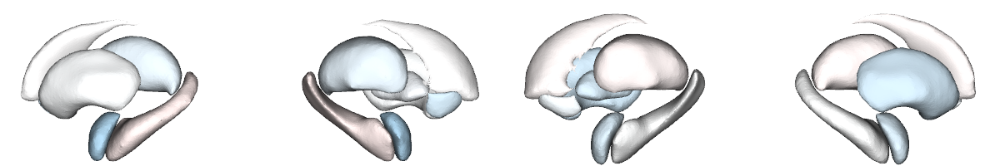

In [97]:
# plot cohen values in nonlesional TLE
# label_text = ['sex + durill', 'sex * durill', 'sex + ao', 'sex * ao']

plot_subcortical(result_dicts['cohen_tle_nonlesional_sv'][3], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

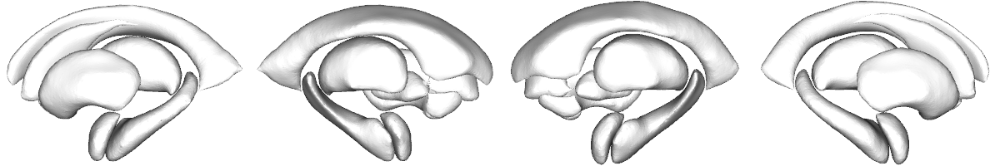

In [98]:
# plot p-sig areas

sig_mask = np.where(result_dicts['q_tle_nonlesional_sv'][3] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, nan_color=(1,1,1,1), interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [99]:
# MTS 
q_sv_mts = pd.Series(
    result_dicts["q_tle_mts_sv"][3],
    index=sv_tle.columns,
    name="pFDR"
)

q_sv_mts[q_sv_mts < 0.05].index

Index([], dtype='object')

In [100]:
# Non-lesional 
q_sv_nonlesional = pd.Series(
    result_dicts["q_tle_nonlesional_sv"][3],
    index=sv_tle.columns,
    name="pFDR"
)

q_sv_nonlesional[q_sv_nonlesional < 0.05].index

Index([], dtype='object')

In [101]:
result_dicts["cohen_tle_mts_sv"][3].min(), result_dicts["cohen_tle_mts_sv"][3].max()

(-0.0731080646184757, 0.06792815797552858)

In [102]:
result_dicts["cohen_tle_nonlesional_sv"][3].min(), result_dicts["cohen_tle_nonlesional_sv"][3].max()

(-0.06468747298627255, 0.020127778246174056)